In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Project path
data_path = r"C:\Users\main\Desktop\Projects\Retail Demand Forecasting"

# Load cleaned dataset
df = pd.read_csv(
    data_path + r"\outputs\retail_demand_forecasting_cleaned.csv"
)

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Sort data chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Create folder for graphs
eda_path = data_path + r"\outputs\eda"
os.makedirs(eda_path, exist_ok=True)

# Graph styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

print("EDA environment prepared successfully!")
print("Dataset Shape:", df.shape)

EDA environment prepared successfully!
Dataset Shape: (198, 16)


In [3]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

In [4]:
df["Units_Sold"].describe()

count    192.000000
mean      47.807292
std       74.671563
min        0.000000
25%       35.000000
50%       41.000000
75%       46.250000
max      999.000000
Name: Units_Sold, dtype: float64

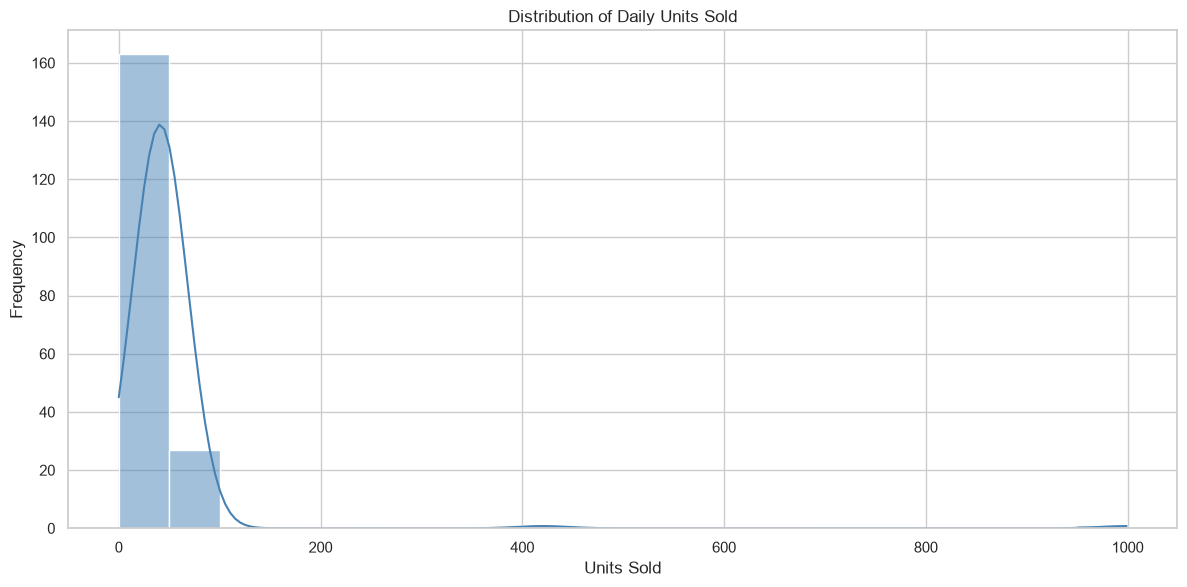

In [22]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Units_Sold",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Daily Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    eda_path + r"\01_sales_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

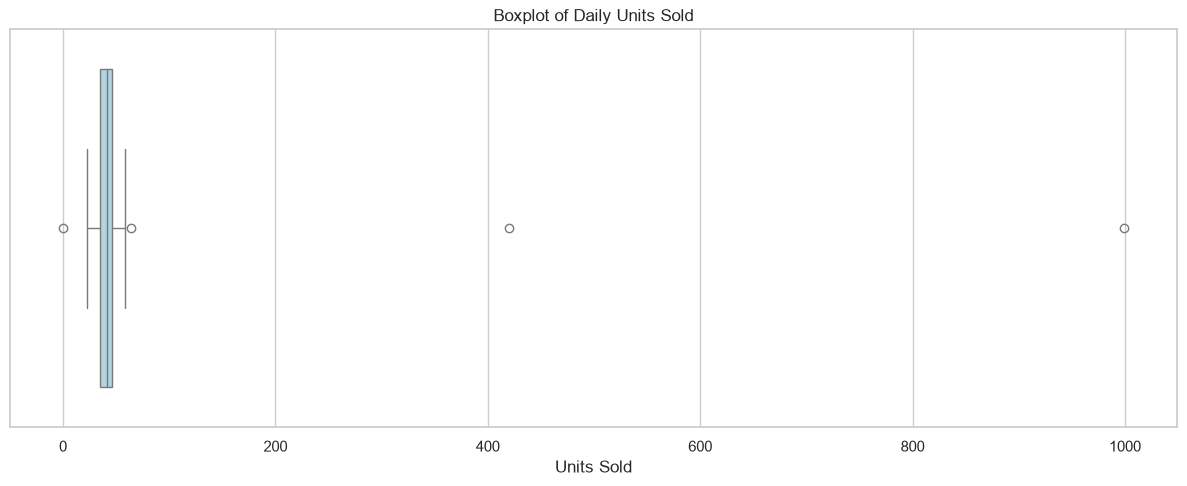

In [23]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="Units_Sold",
    color="lightblue"
)

plt.title("Boxplot of Daily Units Sold")
plt.xlabel("Units Sold")
plt.tight_layout()

plt.savefig(
    eda_path + r"\02_sales_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Time-Series Analysis

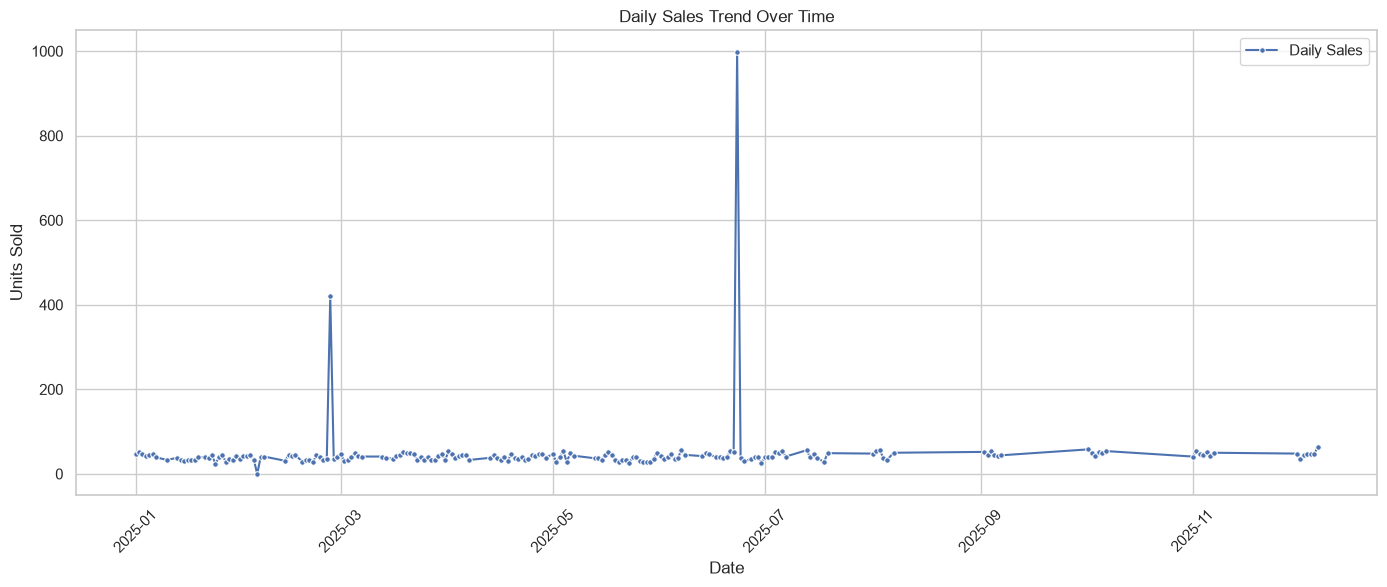

In [24]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="Date",
    y="Units_Sold",
    marker="o",
    markersize=4,
    label="Daily Sales"
)

plt.title("Daily Sales Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\03_daily_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

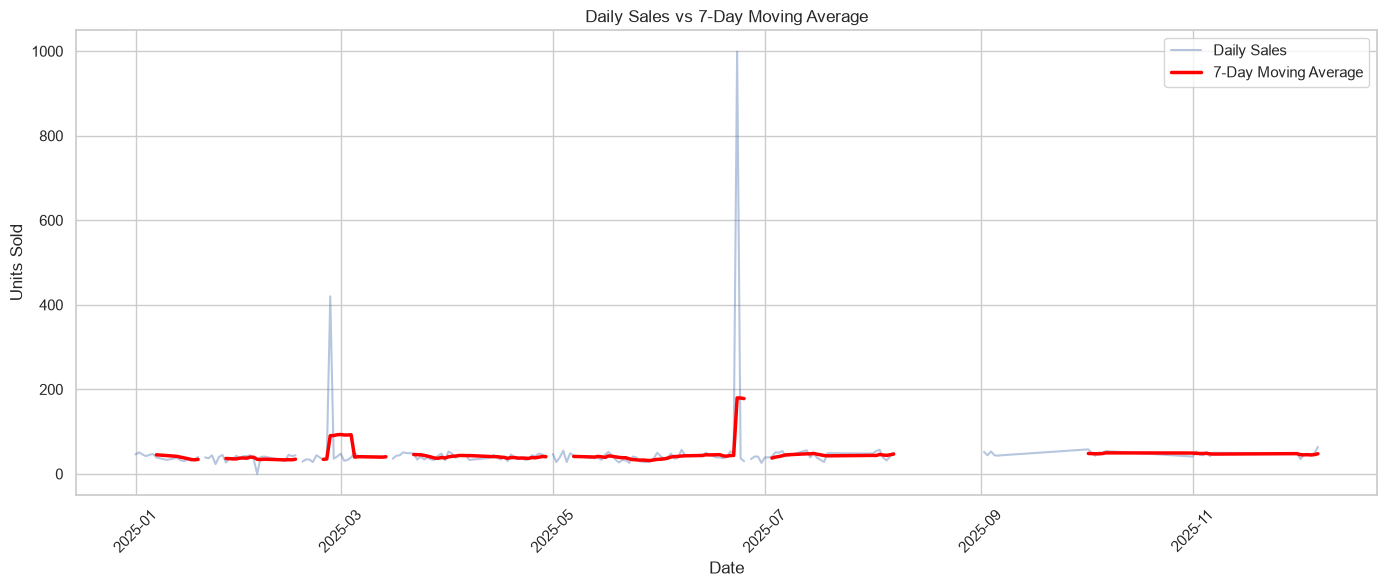

In [25]:
df["7_Day_Moving_Average"] = (
    df["Units_Sold"]
    .rolling(window=7, min_periods=7)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Units_Sold"],
    alpha=0.4,
    label="Daily Sales"
)

plt.plot(
    df["Date"],
    df["7_Day_Moving_Average"],
    linewidth=2.5,
    color="red",
    label="7-Day Moving Average"
)

plt.title("Daily Sales vs 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\04_sales_moving_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

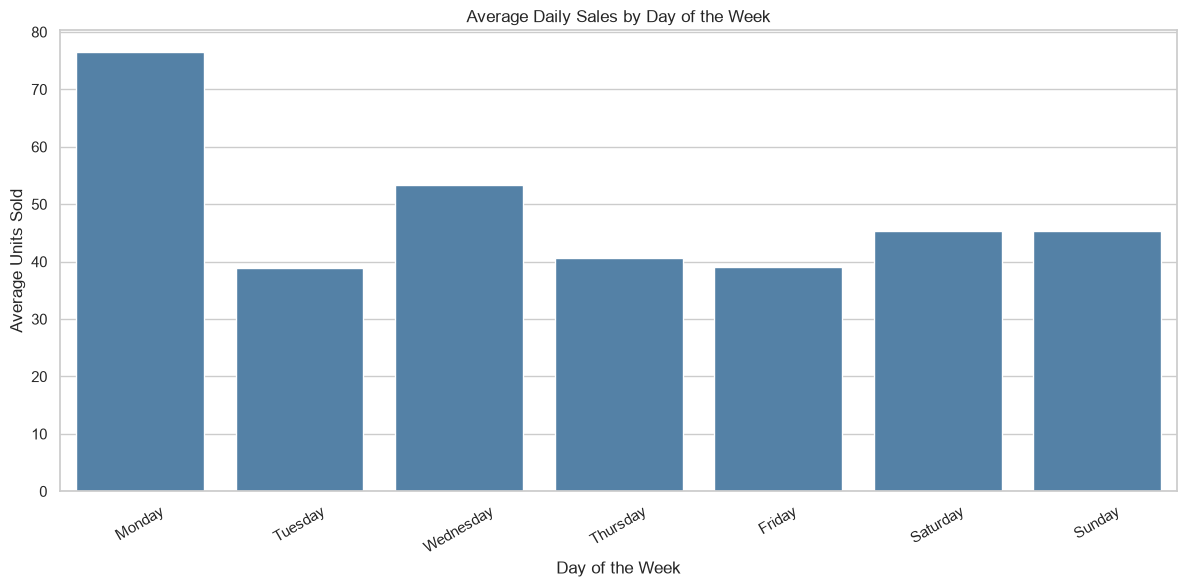

In [26]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("Day_of_Week")["Units_Sold"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_sales,
    x="Day_of_Week",
    y="Units_Sold",
    color="steelblue"
)

plt.title("Average Daily Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    eda_path + r"\05_weekday_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
df["Month"] = df["Date"].dt.month

monthly_sales = (
    df.groupby("Month")["Units_Sold"]
    .mean()
)

print(monthly_sales)

Month
1     38.192308
2     53.545455
3     40.840000
4     40.500000
5     37.346154
6     81.125000
7     44.076923
8     46.500000
9     46.666667
10    50.666667
11    46.857143
12    47.571429
Name: Units_Sold, dtype: float64


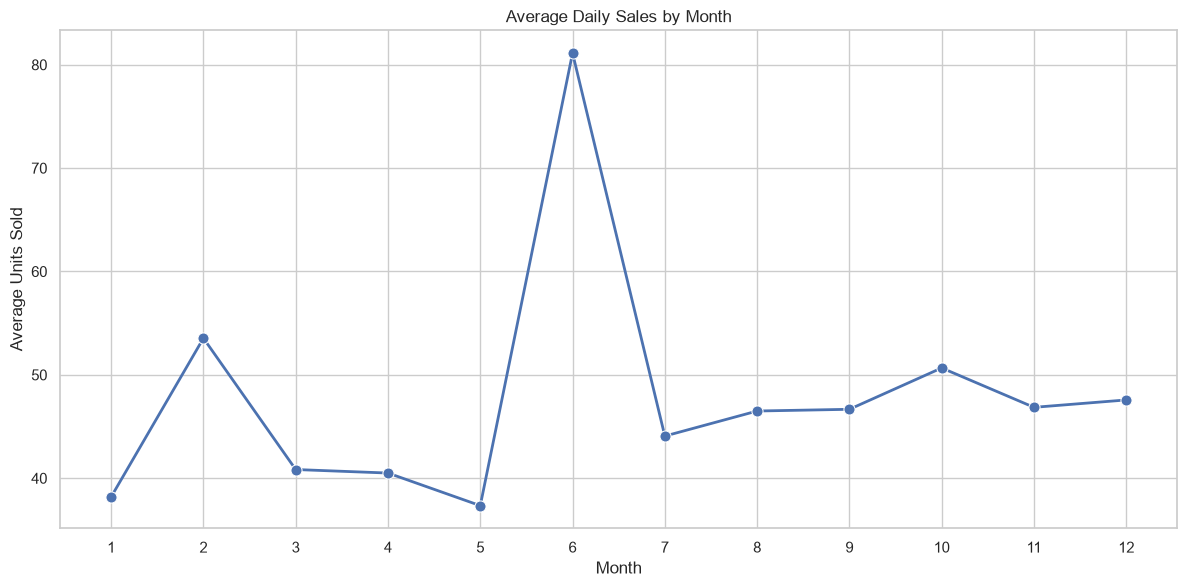

In [27]:
df["Month"] = df["Date"].dt.month

monthly_sales = (
    df.groupby("Month")["Units_Sold"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Units_Sold",
    marker="o",
    markersize=8,
    linewidth=2
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(range(1, 13))
plt.tight_layout()

plt.savefig(
    eda_path + r"\06_monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
promotion_sales = (
    df.groupby("Promotion")["Units_Sold"]
    .agg(["mean", "median", "count"])
)

print(promotion_sales)

                mean  median  count
Promotion                          
No         41.769231    39.0    143
Yes        66.847826    47.0     46


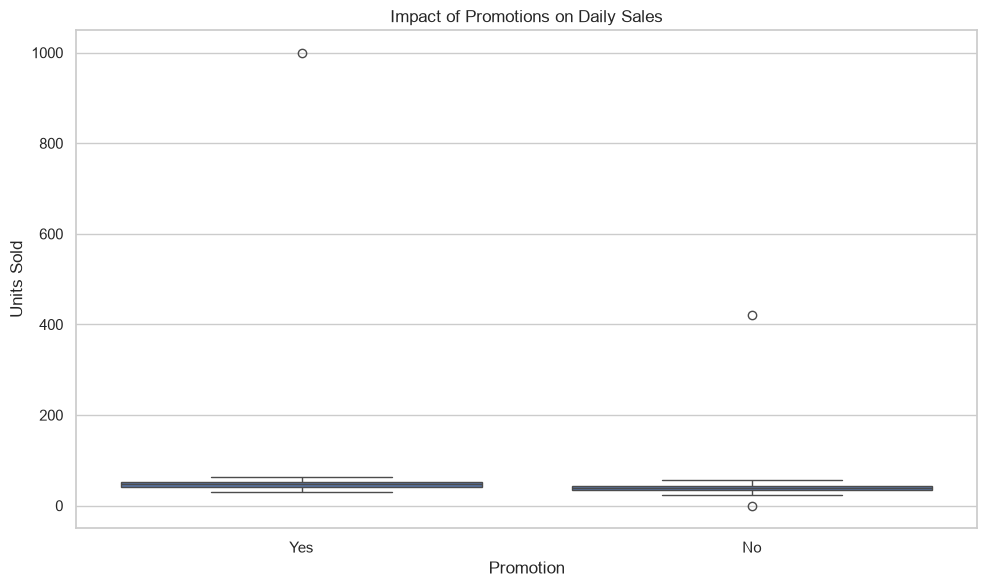

In [28]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Promotion",
    y="Units_Sold"
)

plt.title("Impact of Promotions on Daily Sales")
plt.xlabel("Promotion")
plt.ylabel("Units Sold")
plt.tight_layout()

plt.savefig(
    eda_path + r"\07_promotion_vs_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

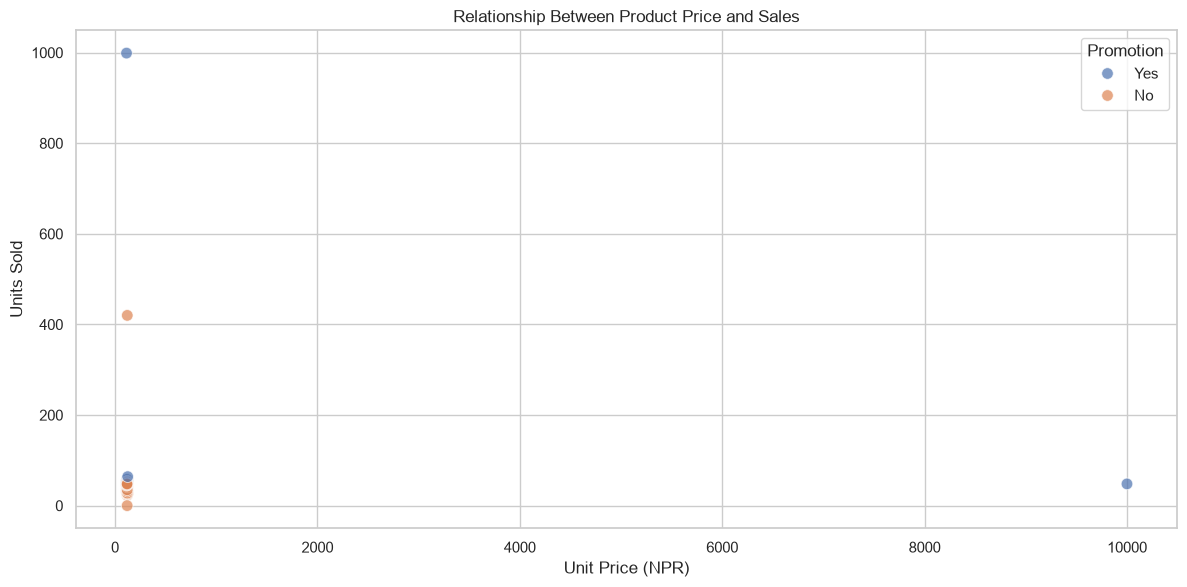

In [29]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Unit_Price_NPR",
    y="Units_Sold",
    hue="Promotion",
    alpha=0.7,
    s=70
)

plt.title("Relationship Between Product Price and Sales")
plt.xlabel("Unit Price (NPR)")
plt.ylabel("Units Sold")
plt.legend(title="Promotion")
plt.tight_layout()

plt.savefig(
    eda_path + r"\08_price_vs_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
correlation = df[
    ["Units_Sold", "Unit_Price_NPR", "Discount_Pct"]
].corr()

print(correlation)

                Units_Sold  Unit_Price_NPR  Discount_Pct
Units_Sold        1.000000       -0.000419      0.152361
Unit_Price_NPR   -0.000419        1.000000      0.133104
Discount_Pct      0.152361        0.133104      1.000000


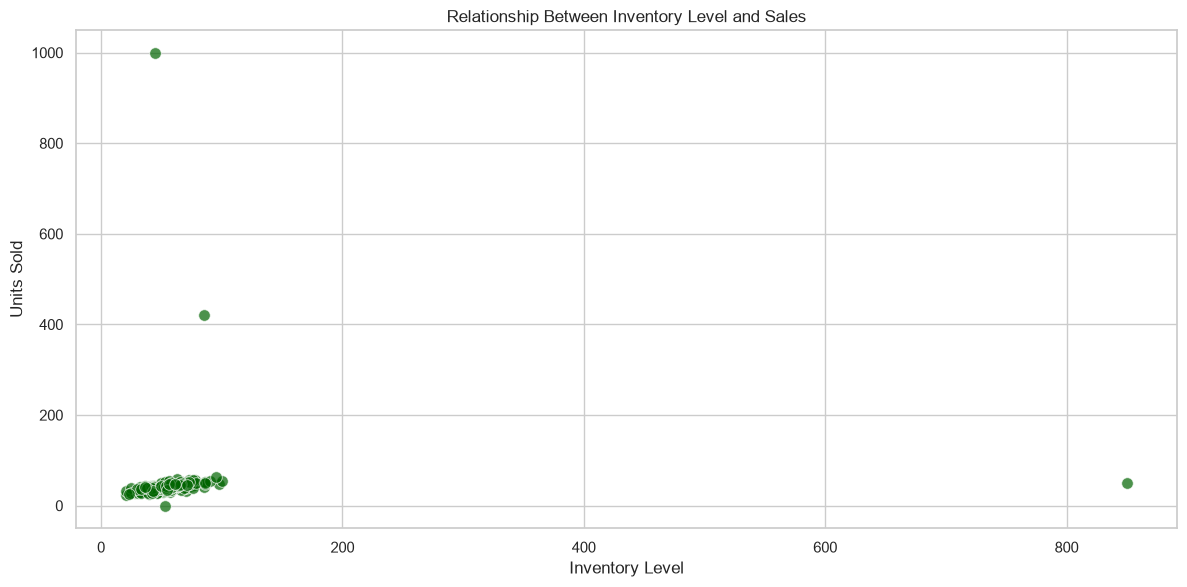

In [30]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Inventory_Level",
    y="Units_Sold",
    alpha=0.7,
    color="darkgreen",
    s=70
)

plt.title("Relationship Between Inventory Level and Sales")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.tight_layout()

plt.savefig(
    eda_path + r"\09_inventory_vs_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

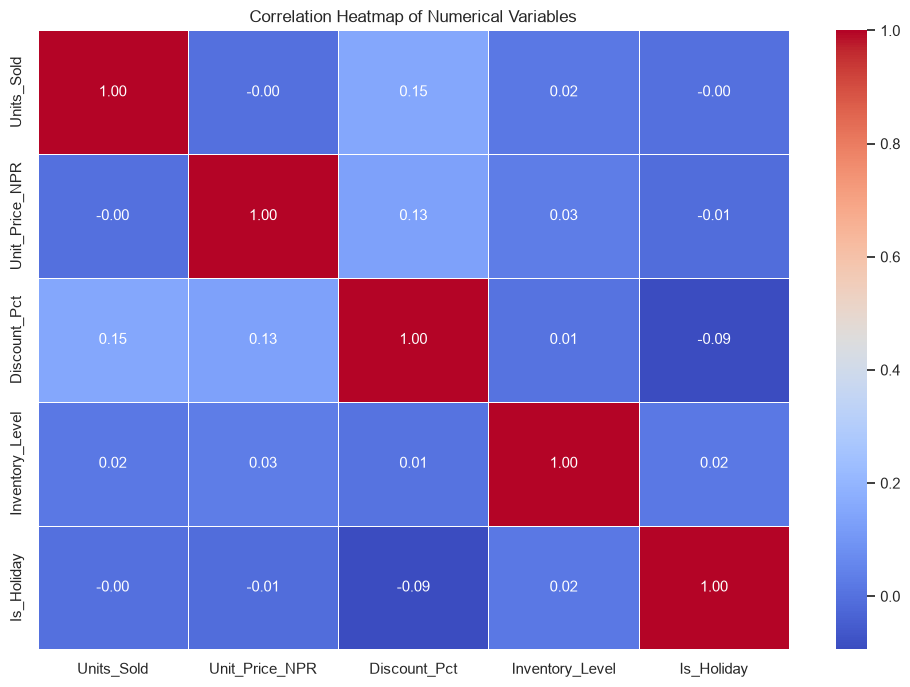

In [31]:
numeric_columns = [
    "Units_Sold",
    "Unit_Price_NPR",
    "Discount_Pct",
    "Inventory_Level",
    "Is_Holiday"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()

plt.savefig(
    eda_path + r"\10_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
import os

eda_path = data_path + r"\outputs\eda"

os.makedirs(eda_path, exist_ok=True)

In [19]:
plt.savefig(
    eda_path + r"\sales_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1200x600 with 0 Axes>